# Credit Risk Prediction — Master Notebook

Notebook này là file thực thi duy nhất dành cho Google Colab. Chọn **Runtime → Run all** để chạy toàn bộ quy trình: setup, EDA, preprocessing, model training, evaluation và kiểm tra deliverables.

Các notebook `01_EDA.ipynb` và `02_Data_Preprocessing.ipynb` vẫn được giữ trong repository như tài liệu/module riêng, nhưng master notebook không gọi hay phụ thuộc vào chúng.

## 0. Environment setup

Clone repository nếu chưa có trong runtime, cài dependencies và chuẩn bị các thư mục đầu ra.

In [1]:
import os
import sys
import subprocess
import shutil
from pathlib import Path

REPO_URL = "https://github.com/DuyTuong101/credit-risk-prediction.git"
REPO_DIR_NAME = "credit-risk-prediction"

def find_project_root(start):
    for candidate in [start, *start.parents]:
        if (
            (candidate / "modules" / "data_processing.py").is_file()
            and (candidate / "modules" / "model_training.py").is_file()
            and (candidate / "data").is_dir()
        ):
            return candidate
    return None

PROJECT_ROOT = find_project_root(Path.cwd())

if PROJECT_ROOT is None:
    clone_dir = Path("/content") / REPO_DIR_NAME
    if clone_dir.exists() and find_project_root(clone_dir) is None:
        shutil.rmtree(clone_dir)
    if not clone_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(clone_dir)], check=True)
    PROJECT_ROOT = find_project_root(clone_dir)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate project root. Verify REPO_URL and repository access."
    )

NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"
FEATURES_DIR = PROJECT_ROOT / "features"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DIR = PROJECT_ROOT / "data" / "raw"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"

for folder in [FEATURES_DIR, PROCESSED_DIR, RAW_DIR, MODELS_DIR, REPORTS_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

os.chdir(NOTEBOOK_DIR)
sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Notebook directory:", Path.cwd())
print("Python:", sys.version)


Project root: /content/credit-risk-prediction
Notebook directory: /content/credit-risk-prediction/notebooks
Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


## 1. Install dependencies

Cài các thư viện được khai báo trong `requirements.txt`. Không cần `nbclient` vì master notebook chạy trực tiếp các bước trong cùng một kernel.

In [2]:
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r", str(PROJECT_ROOT / "requirements.txt")],
    check=True
)
print("Dependencies are ready.")


Dependencies are ready.


## 2. Exploratory Data Analysis (EDA)

Đọc dữ liệu gốc, xem cấu trúc và thống kê, kiểm tra missing values/duplicates, phân phối target, giá trị bất thường, phân phối biến phân loại và tương quan. Các bảng và biểu đồ được hiển thị trực tiếp trong master notebook.

### 1. Import Libraries and Load Data

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display and report figure directory
sns.set_theme(style="whitegrid", palette="muted")
FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Read raw data
df = pd.read_csv("../data/raw/credit_risk_dataset.csv")
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset shape: 32581 rows, 12 columns


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


### 2. Descriptive Statistics, Duplicates & Missing Values

In [4]:
print("=== 1. DATA TYPES INFORMATION ===")
print(df.info())

print(f"\n=== 2. NUMBER OF DUPLICATE ROWS: {df.duplicated().sum()} ===")

print("\n=== 3. MISSING VALUES STATISTICS ===")
missing_df = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
display(missing_df[missing_df['Missing Count'] > 0])

print("\n=== 4. NUMERICAL FEATURES DESCRIPTIVE STATISTICS ===")
display(df.describe().T)

print("\n=== 5. CATEGORICAL FEATURES STATISTICS ===")
display(df.describe(include='object').T)

=== 1. DATA TYPES INFORMATION ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ 

,Missing Count,Missing (%)
person_emp_length,895,2.75
loan_int_rate,3116,9.56



=== 4. NUMERICAL FEATURES DESCRIPTIVE STATISTICS ===


,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00



=== 5. CATEGORICAL FEATURES STATISTICS ===


,count,unique,top,freq
person_home_ownership,32581,4,RENT,16446
loan_intent,32581,6,EDUCATION,6453
loan_grade,32581,7,A,10777
cb_person_default_on_file,32581,2,N,26836


### 3. Target Variable Distribution (loan_status)

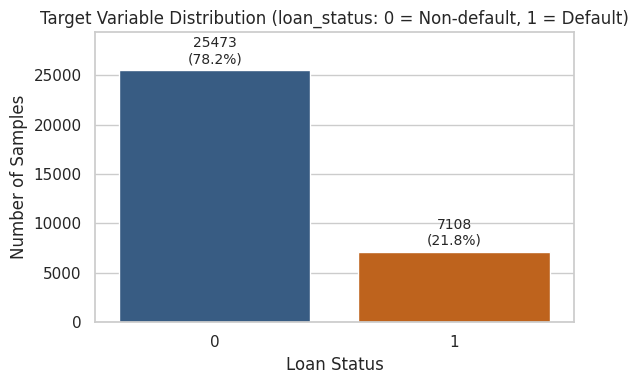

In [5]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='loan_status', hue='loan_status', palette=['#2b5c8f', '#d95f02'], legend=False)
plt.title("Target Variable Distribution (loan_status: 0 = Non-default, 1 = Default)")
plt.xlabel("Loan Status")
plt.ylabel("Number of Samples")

# Display count and percentage on bars
total = len(df)
for p in ax.patches:
    count = int(p.get_height())
    pct = 100 * count / total
    ax.annotate(f'{count}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2., count),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.ylim(0, total * 0.9)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_target_distribution.png", dpi=300)
plt.show()

### 4. Outliers and Invalid Values Detection

=== 4.1 Constraint violations in RAW data ===


,rows_violating
person_age > 100,5
person_emp_length > 60,2
person_emp_length > age - 14,2
cb_person_cred_hist_length > age - 18,781
|loan_amnt/income - loan_percent_income| > 0.01,388
"person_income > 1,000,000",9
duplicated rows,165



=== 4.2 IQR outlier summary (RAW data) ===


,min,max,lower_fence,upper_fence,n_outliers,outliers_%,skewness
feature,,,,,,,
person_age,20.00,144.00,12.50,40.50,1494,4.59,2.58
person_income,4000.00,6000000.00,-22550.00,140250.00,1484,4.55,32.87
person_emp_length,0.00,123.00,-5.50,14.50,853,2.69,2.61
loan_amnt,500.00,35000.00,-5800.00,23000.00,1689,5.18,1.19
loan_int_rate,5.42,23.22,-0.46,21.83,6,0.02,0.21
loan_percent_income,0.00,0.83,-0.12,0.44,651,2.00,1.06
cb_person_cred_hist_length,2.00,30.00,-4.50,15.50,1142,3.51,1.66


-> duplicate rows                                removed   165 | remaining  32416
-> person_age > 100                              removed     5 | remaining  32411
-> emp_length > 60 or > age - 14                 removed     2 | remaining  32409
==> Total removed: 172 | final samples: 32409

=== 4.2 IQR outlier summary (CLEANED data) ===


,min,max,lower_fence,upper_fence,n_outliers,outliers_%,skewness
feature,,,,,,,
person_age,20.00,94.00,12.50,40.50,1486,4.59,1.94
person_income,4000.00,2039784.00,-22550.00,140250.00,1474,4.55,9.78
person_emp_length,0.00,41.00,-5.50,14.50,850,2.70,1.25
loan_amnt,500.00,35000.00,-5875.00,23125.00,1678,5.18,1.19
loan_int_rate,5.42,23.22,-0.46,21.83,6,0.02,0.21
loan_percent_income,0.00,0.83,-0.12,0.44,649,2.00,1.06
cb_person_cred_hist_length,2.00,30.00,-4.50,15.50,1138,3.51,1.66


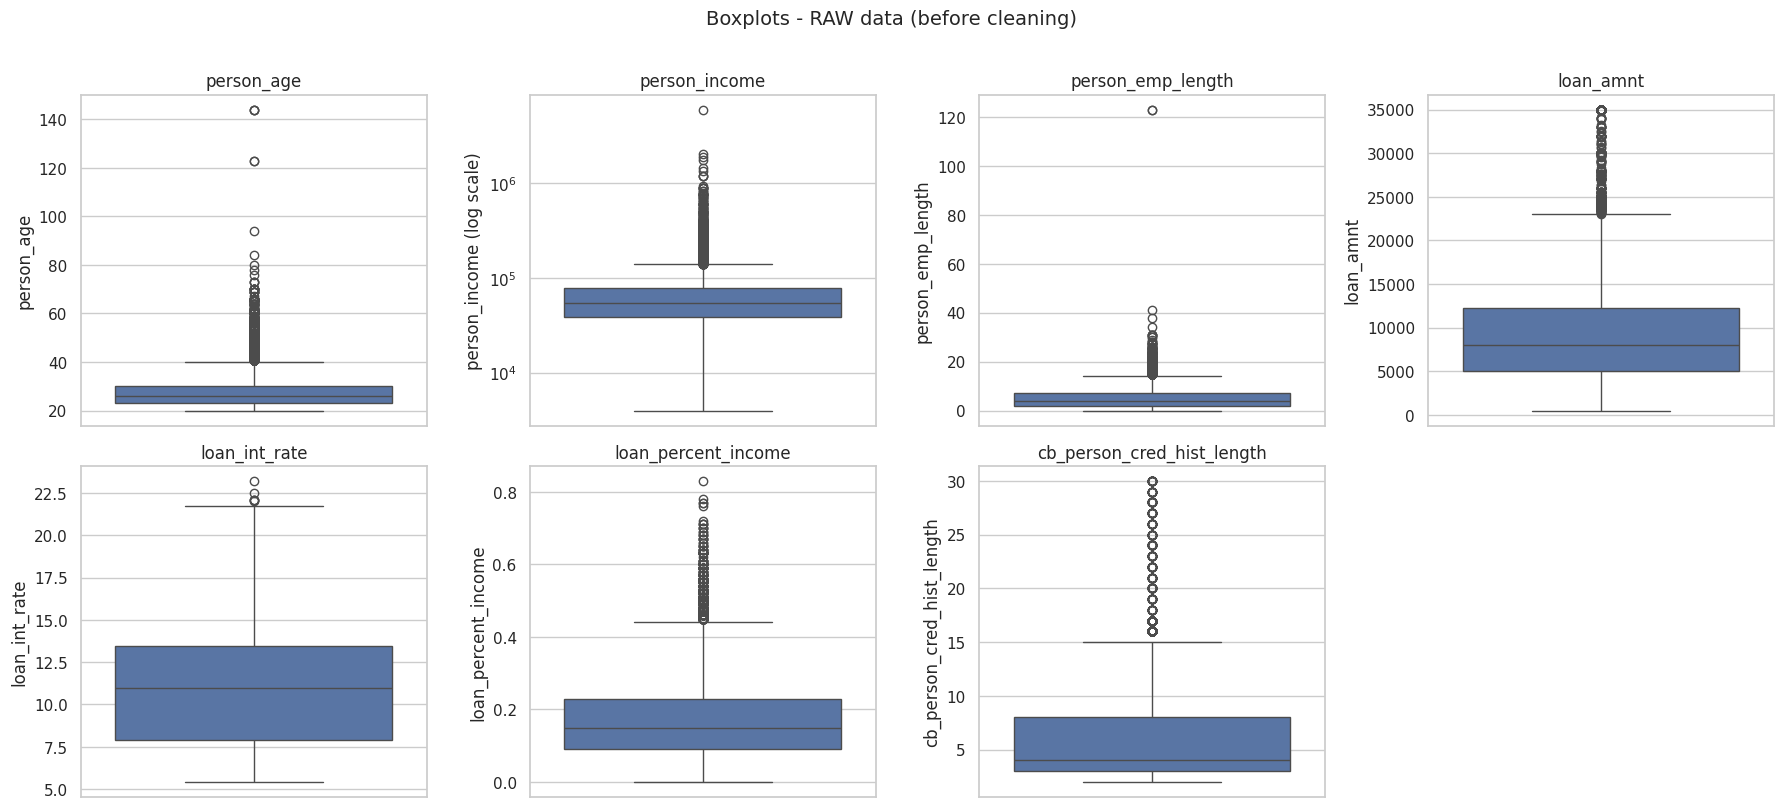

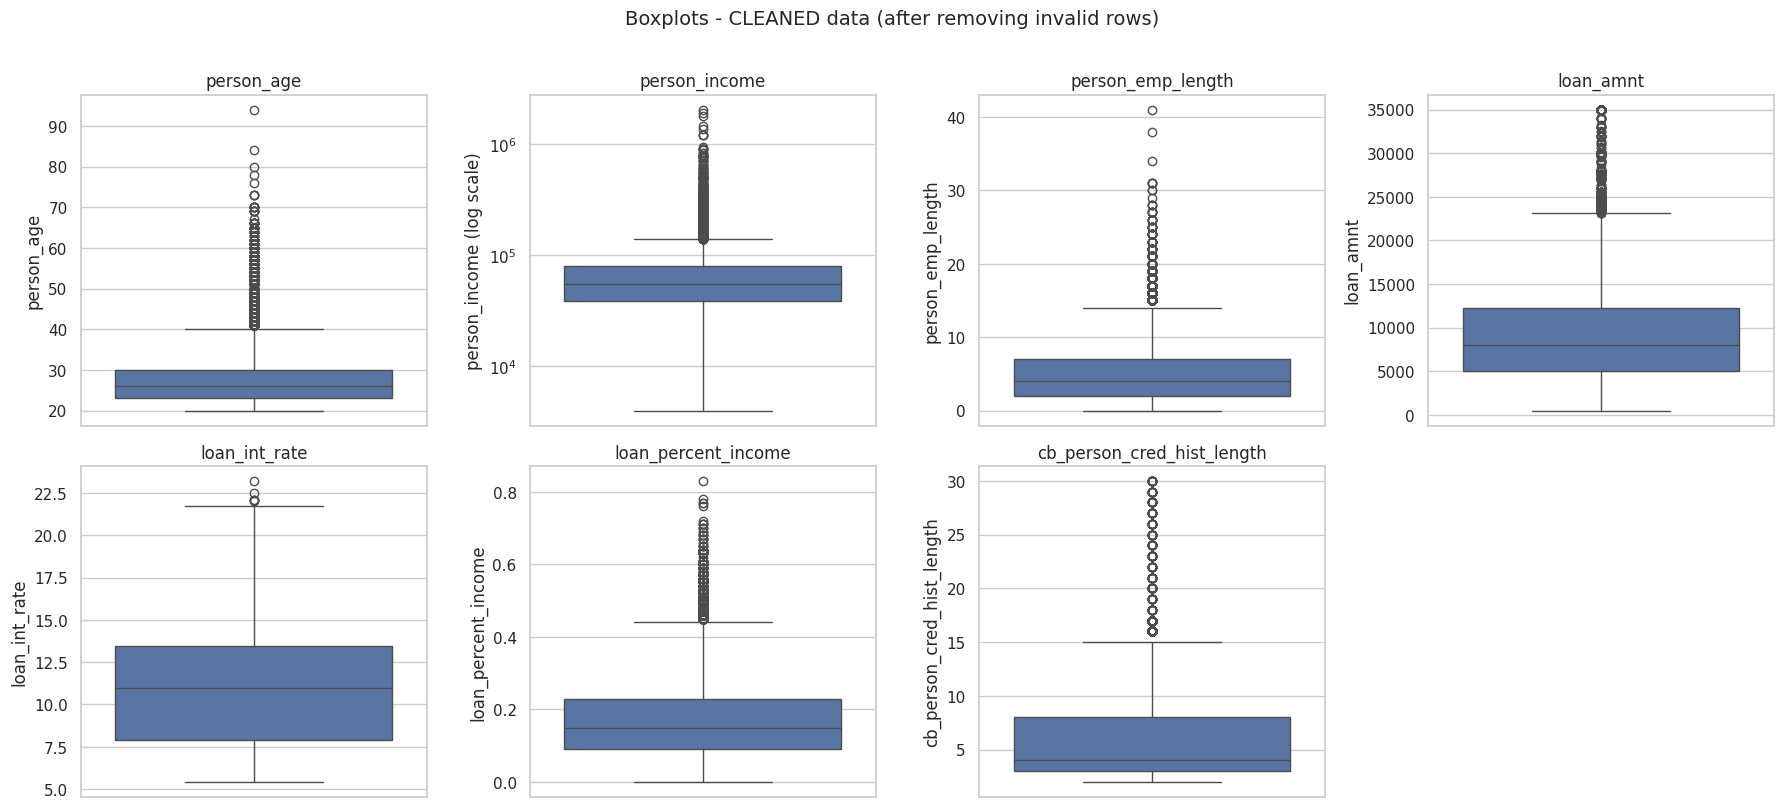

Records with person_age > 100:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


Records with person_emp_length > 60 or > age - 14:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


In [6]:
import sys

sys.path.append(os.path.abspath(".."))
from modules.data_processing import audit_constraints, clean_raw_data

num_cols = [
    'person_age', 'person_income', 'person_emp_length',
    'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'
]

print("=== 4.1 Constraint violations in RAW data ===")
display(audit_constraints(df).to_frame("rows_violating"))

def iqr_summary(data: pd.DataFrame, cols: list) -> pd.DataFrame:
    rows = []
    for c in cols:
        s = data[c].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((s < lo) | (s > hi)).sum())
        rows.append({
            "feature": c, "min": s.min(), "max": s.max(),
            "lower_fence": round(lo, 2), "upper_fence": round(hi, 2),
            "n_outliers": n_out, "outliers_%": round(100 * n_out / len(s), 2),
            "skewness": round(s.skew(), 2),
        })
    return pd.DataFrame(rows).set_index("feature")

print("\n=== 4.2 IQR outlier summary (RAW data) ===")
display(iqr_summary(df, num_cols))

# Apply the cleaning rules used in the pipeline, then re-check
df_clean = clean_raw_data(df, verbose=True)
print("\n=== 4.2 IQR outlier summary (CLEANED data) ===")
display(iqr_summary(df_clean, num_cols))

def plot_boxplots(data: pd.DataFrame, title: str, path: str):
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    axes = axes.flatten()
    for i, col in enumerate(num_cols):
        sns.boxplot(data=data, y=col, ax=axes[i], color='#4c72b0')
        axes[i].set_title(f"{col}")
        if col == 'person_income':          # heavy right skew -> log scale
            axes[i].set_yscale('log')
            axes[i].set_ylabel('person_income (log scale)')
    axes[-1].axis('off')
    fig.suptitle(title, fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()


plot_boxplots(df, "Boxplots - RAW data (before cleaning)",
              f"{FIG_DIR}/02a_boxplots_raw.png")
plot_boxplots(df_clean, "Boxplots - CLEANED data (after removing invalid rows)",
              f"{FIG_DIR}/02b_boxplots_cleaned.png")


print("Records with person_age > 100:")
display(df[df['person_age'] > 100])

print("Records with person_emp_length > 60 or > age - 14:")
display(df[df['person_emp_length'] > df['person_age'] - 14])


### 5. Categorical Distributions by loan_status

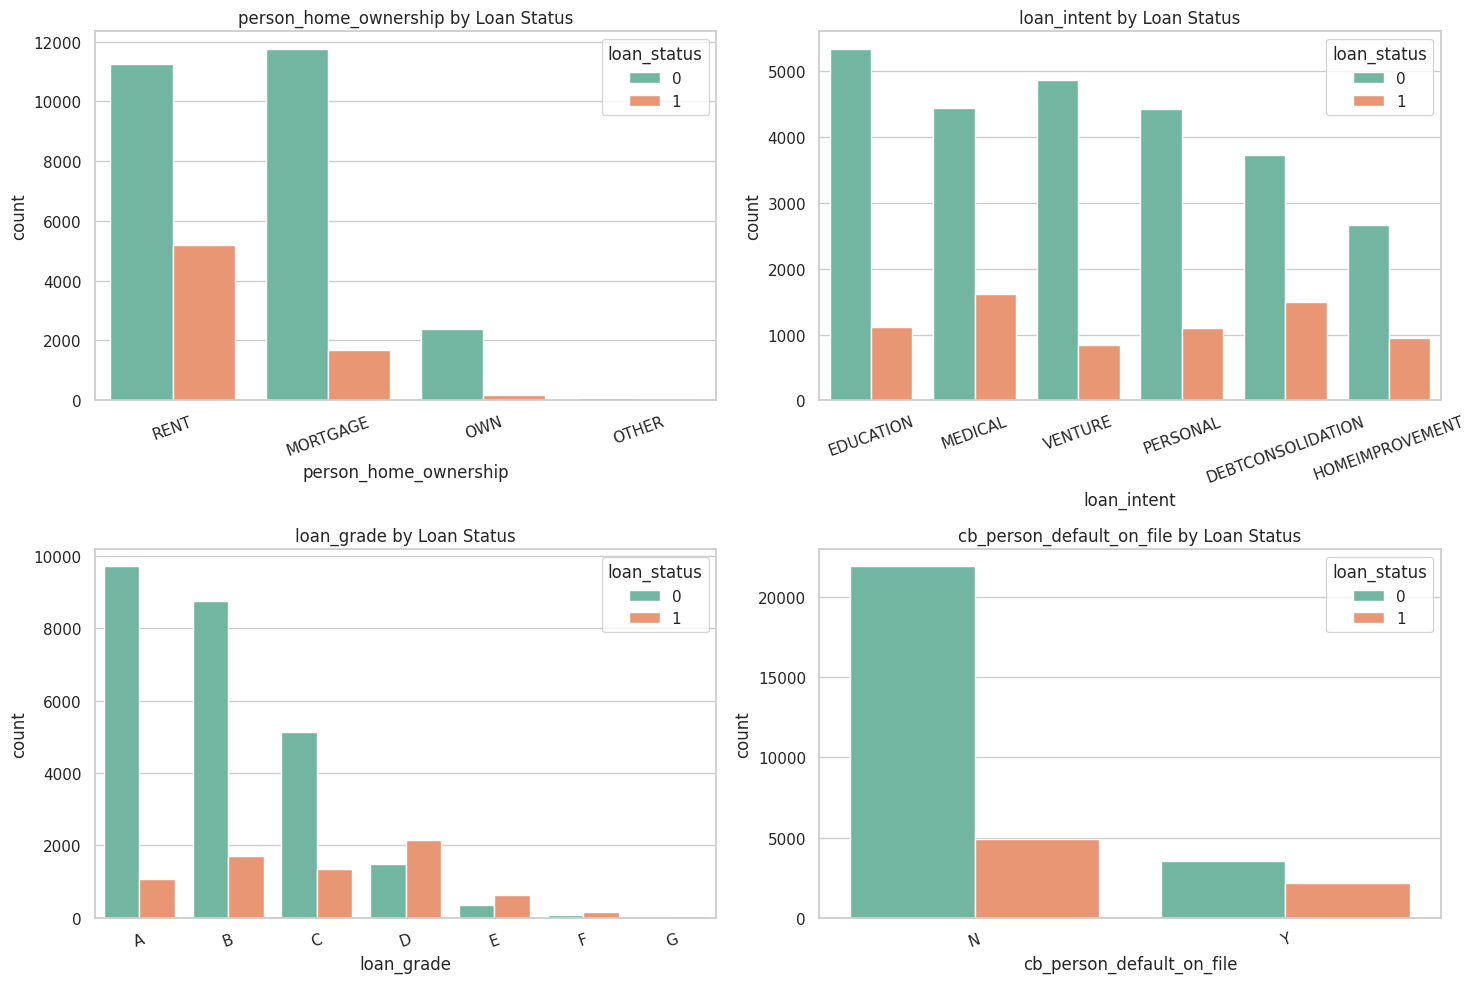

In [7]:
cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    order = sorted(df[col].unique()) if col == 'loan_grade' else df[col].value_counts().index
    sns.countplot(data=df, x=col, hue='loan_status', order=order, ax=axes[i], palette='Set2')
    axes[i].set_title(f"{col} by Loan Status")
    axes[i].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_categorical_distributions.png", dpi=300)
plt.show()

### 6. Correlation Heatmap

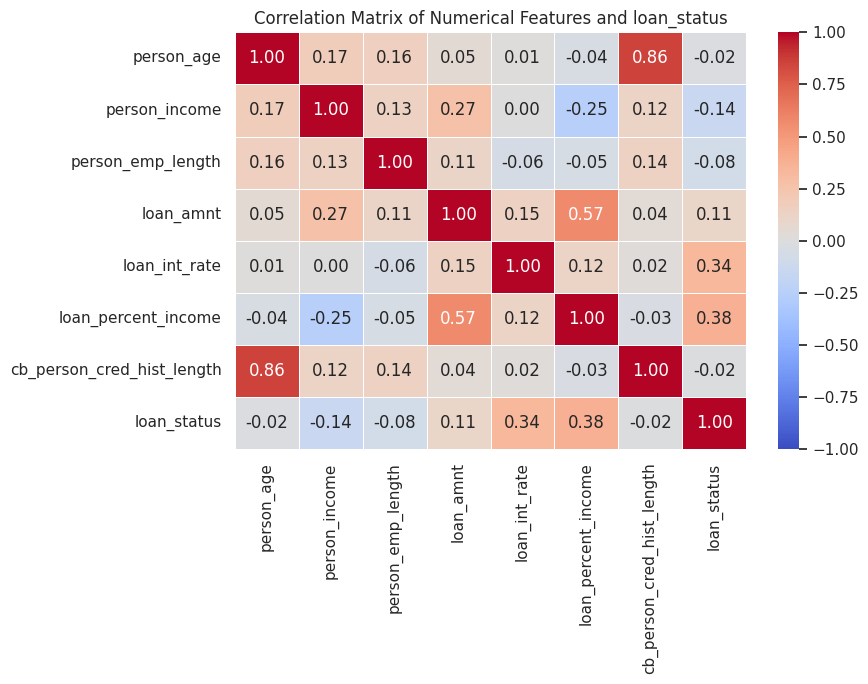

In [8]:
plt.figure(figsize=(9, 7))
corr_matrix = df[num_cols + ['loan_status']].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Numerical Features and loan_status")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/04_correlation_heatmap.png", dpi=300)
plt.show()

## 3. Data Preprocessing

Làm sạch dữ liệu, chia train/test và tạo 8 cấu hình feature. Các preprocessing transformers chỉ được fit trên tập train để tránh data leakage.

### 1. Import Libraries and Load Data

In [9]:
import os
import sys
import urllib.request
import numpy as np
import pandas as pd

sys.path.append(os.path.abspath(".."))
from modules.data_processing import (
    clean_raw_data, split_data, build_preprocessing_pipeline,
    get_feature_names, save_features,
)

RAW_PATH = "../data/raw/credit_risk_dataset.csv"
RAW_URL = "https://raw.githubusercontent.com/DuyTuong101/credit-risk-prediction/main/data/raw/credit_risk_dataset.csv"
FEATURES_DIR = "../features"
PROCESSED_DIR = "../data/processed"
for d in (os.path.dirname(RAW_PATH), FEATURES_DIR, PROCESSED_DIR):
    os.makedirs(d, exist_ok=True)

if not os.path.exists(RAW_PATH):
    urllib.request.urlretrieve(RAW_URL, RAW_PATH)

df_raw = pd.read_csv(RAW_PATH)
print("Initial shape:", df_raw.shape)

Initial shape: (32581, 12)


### 2. Data Cleaning and Train/Test Split (Preventing Data Leakage)

In [10]:
df_clean = clean_raw_data(df_raw)
df_clean.to_csv(f"{PROCESSED_DIR}/credit_risk_cleaned.csv", index=False)


X_train, X_test, y_train, y_test = split_data(df_clean, target_col="loan_status")

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Default rate Train: {y_train.mean():.4f} | Test: {y_test.mean():.4f}")


-> duplicate rows                                removed   165 | remaining  32416
-> person_age > 100                              removed     5 | remaining  32411
-> emp_length > 60 or > age - 14                 removed     2 | remaining  32409
==> Total removed: 172 | final samples: 32409
X_train: (25927, 11) | X_test: (6482, 11)
Default rate Train: 0.2187 | Test: 0.2188


### 3. Run Baseline Configuration and Save Features

In [11]:
num_cols = ['person_age', 'person_income', 'person_emp_length',
            'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
ordinal_cols = ['loan_grade']
nominal_cols = ['person_home_ownership', 'loan_intent', 'cb_person_default_on_file']

configs = {
    "baseline":         dict(impute_strategy="median", scaler_type="standard"),
    "minmax_0_1":       dict(impute_strategy="median", scaler_type="minmax", feature_range=(0, 1)),
    "minmax_m1_1":      dict(impute_strategy="median", scaler_type="minmax", feature_range=(-1, 1)),
    "robust_logincome": dict(impute_strategy="median", scaler_type="robust", log_cols=["person_income"]),
    "knn_indicator":    dict(impute_strategy="knn", scaler_type="standard", add_missing_indicator=True),
    "standard_pca90":   dict(impute_strategy="median", scaler_type="standard", pca_variance=0.90),
    "standard_pca95":   dict(impute_strategy="median", scaler_type="standard", pca_variance=0.95),
    "minmax_pca95":     dict(impute_strategy="median", scaler_type="minmax", feature_range=(0, 1), pca_variance=0.95),
}

summary_rows = []
for name, cfg in configs.items():
    pipe = build_preprocessing_pipeline(num_cols, ordinal_cols, nominal_cols, **cfg)
    X_tr = pipe.fit_transform(X_train)           # fit CHỈ trên train
    X_te = pipe.transform(X_test)                # test chỉ transform

    assert not np.isnan(X_tr).any() and not np.isnan(X_te).any()
    assert X_tr.shape[1] == X_te.shape[1] == len(get_feature_names(pipe))

    save_features(name, pipe, X_tr, X_te, y_train, y_test, cfg,
                  out_dir=FEATURES_DIR, save_pipeline=(name == "baseline"))

    summary_rows.append({
        "Config": name,
        "Imputer": cfg.get("impute_strategy"),
        "Scaler": cfg.get("scaler_type"),
        "Log cols": ",".join(cfg.get("log_cols", [])) or "-",
        "Missing indicator": cfg.get("add_missing_indicator", False),
        "PCA variance": cfg.get("pca_variance") or "-",
        "n_features": X_tr.shape[1],
    })

print("Baseline features:", get_feature_names(
    build_preprocessing_pipeline(num_cols, ordinal_cols, nominal_cols).fit(X_train)))
display(pd.DataFrame(summary_rows))

Baseline features: ['num__person_age', 'num__person_income', 'num__person_emp_length', 'num__loan_amnt', 'num__loan_int_rate', 'num__loan_percent_income', 'num__cb_person_cred_hist_length', 'ord__loan_grade', 'nom__person_home_ownership_OTHER', 'nom__person_home_ownership_OWN', 'nom__person_home_ownership_RENT', 'nom__loan_intent_EDUCATION', 'nom__loan_intent_HOMEIMPROVEMENT', 'nom__loan_intent_MEDICAL', 'nom__loan_intent_PERSONAL', 'nom__loan_intent_VENTURE', 'nom__cb_person_default_on_file_Y']


,Config,Imputer,Scaler,Log cols,Missing indicator,PCA variance,n_features
0,baseline,median,standard,-,False,-,17
1,minmax_0_1,median,minmax,-,False,-,17
2,minmax_m1_1,median,minmax,-,False,-,17
3,robust_logincome,median,robust,person_income,False,-,17
4,knn_indicator,knn,standard,-,True,-,19
5,standard_pca90,median,standard,-,False,0.9,8
6,standard_pca95,median,standard,-,False,0.95,11
7,minmax_pca95,median,minmax,-,False,0.95,8


### 4. Test Configurable Pipeline Options

In [12]:
import glob, json
print(sorted(os.path.basename(p) for p in glob.glob(f"{FEATURES_DIR}/*")))
y_tr, y_te = np.load(f"{FEATURES_DIR}/y_train.npy"), np.load(f"{FEATURES_DIR}/y_test.npy")
for name in configs:
    a = np.load(f"{FEATURES_DIR}/X_train_{name}.npy"); b = np.load(f"{FEATURES_DIR}/X_test_{name}.npy")
    assert a.shape[0] == len(y_tr) and b.shape[0] == len(y_te) and a.shape[1] == b.shape[1]
print("OK: X/y align", len(configs), "configs")

['X_test_baseline.npy', 'X_test_knn_indicator.npy', 'X_test_minmax_-1_1.npy', 'X_test_minmax_0_1.npy', 'X_test_minmax_m1_1.npy', 'X_test_minmax_pca95.npy', 'X_test_robust_logincome.npy', 'X_test_standard_pca90.npy', 'X_test_standard_pca95.npy', 'X_train_baseline.npy', 'X_train_knn_indicator.npy', 'X_train_minmax_-1_1.npy', 'X_train_minmax_0_1.npy', 'X_train_minmax_m1_1.npy', 'X_train_minmax_pca95.npy', 'X_train_robust_logincome.npy', 'X_train_standard_pca90.npy', 'X_train_standard_pca95.npy', 'config_baseline.json', 'config_knn_indicator.json', 'config_minmax_0_1.json', 'config_minmax_m1_1.json', 'config_minmax_pca95.json', 'config_robust_logincome.json', 'config_standard_pca90.json', 'config_standard_pca95.json', 'feature_names_baseline.json', 'feature_names_knn_indicator.json', 'feature_names_minmax_0_1.json', 'feature_names_minmax_m1_1.json', 'feature_names_minmax_pca95.json', 'feature_names_robust_logincome.json', 'feature_names_standard_pca90.json', 'feature_names_standard_pca95.j

In [13]:
# Restore Path objects after the preprocessing section uses relative string paths.
FEATURES_DIR = PROJECT_ROOT / "features"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"
print("Output directories:", FEATURES_DIR, PROCESSED_DIR, MODELS_DIR, REPORTS_DIR)


Output directories: /content/credit-risk-prediction/features /content/credit-risk-prediction/data/processed /content/credit-risk-prediction/models /content/credit-risk-prediction/reports


## 4. Model Training and Evaluation

Sử dụng hàm `train_and_evaluate()` hiện có trong `modules/model_training.py`. So sánh Logistic Regression, SVM và Random Forest bằng Stratified 3-fold Cross Validation, sau đó đánh giá mô hình tốt nhất trên held-out test set.

In [14]:
import json
import pandas as pd
from IPython.display import display
from modules.model_training import train_and_evaluate

CLEANED_DATA_PATH = PROCESSED_DIR / "credit_risk_cleaned.csv"
if not CLEANED_DATA_PATH.is_file():
    raise FileNotFoundError(
        "The cleaned dataset was not produced by the preprocessing step."
    )

df_clean = pd.read_csv(CLEANED_DATA_PATH)
print("Cleaned dataset shape:", df_clean.shape)
print("Target distribution:")
display(df_clean["loan_status"].value_counts(normalize=True).rename("proportion"))

training_results = train_and_evaluate(
    df=df_clean,
    target_col="loan_status",
    test_size=0.2,
    cv_folds=3,
    random_state=42,
    scaler="standard",
    numeric_imputation="median",
    categorical_imputation="most_frequent",
    model_names=(
        "logistic_regression",
        "svm",
        "random_forest",
    ),
    models_dir=MODELS_DIR,
    reports_dir=REPORTS_DIR,
)

print("Cross-validation comparison (sorted by mean F1):")
display(training_results["comparison"])

print("Held-out test metrics:")
display(pd.DataFrame([training_results["test_metrics"]]).T.rename(columns={0: "value"}))
print("Best model saved to:", training_results["model_path"])


Cleaned dataset shape: (32409, 12)
Target distribution:


,proportion
loan_status,
0,0.781295
1,0.218705


Cross-validation comparison (sorted by mean F1):


,model,cv_f1_mean,cv_f1_std,cv_roc_auc_mean
2,random_forest,0.813518,0.003051,0.929195
1,svm,0.736882,0.008685,0.908002
0,logistic_regression,0.643265,0.005994,0.870318


Held-out test metrics:


,value
selected_model,random_forest
selection_metric,mean cross-validation F1
scaler,standard
feature_range,None
pca_variance,None
numeric_imputation,median
categorical_imputation,most_frequent
models_compared,"[logistic_regression, svm, random_forest]"
model_parameters,"{'logistic_regression': {'C': 1.0, 'class_weig..."
accuracy,0.933817


Best model saved to: /content/credit-risk-prediction/models/best_model.joblib


## 5. Verify Generated Deliverables

Kiểm tra các file mô hình, báo cáo đánh giá và feature arrays đã được tạo đầy đủ.

In [15]:
expected_outputs = [
    MODELS_DIR / "best_model.joblib",
    REPORTS_DIR / "model_comparison.csv",
    REPORTS_DIR / "test_metrics.json",
    REPORTS_DIR / "classification_report.json",
    REPORTS_DIR / "confusion_matrix.csv",
    FEATURES_DIR / "X_train_baseline.npy",
    FEATURES_DIR / "X_test_baseline.npy",
    FEATURES_DIR / "y_train.npy",
    FEATURES_DIR / "y_test.npy",
]

verification = pd.DataFrame({
    "file": [str(p.relative_to(PROJECT_ROOT)) for p in expected_outputs],
    "exists": [p.is_file() for p in expected_outputs],
})
display(verification)

missing = verification.loc[~verification["exists"], "file"].tolist()
if missing:
    raise FileNotFoundError("Missing expected output(s): " + ", ".join(missing))

print("\nAll required outputs in this notebook's verification list exist.")


,file,exists
0,models/best_model.joblib,True
1,reports/model_comparison.csv,True
2,reports/test_metrics.json,True
3,reports/classification_report.json,True
4,reports/confusion_matrix.csv,True
5,features/X_train_baseline.npy,True
6,features/X_test_baseline.npy,True
7,features/y_train.npy,True
8,features/y_test.npy,True



All required outputs in this notebook's verification list exist.


## 6. Pipeline Completed

Sau khi tất cả cell chạy thành công, các artifact được lưu trong repository tại `reports/`, `features/` và `models/`.

In [16]:
print("Master notebook pipeline completed successfully.")
print("EDA figures:", FIG_DIR)
print("Cleaned data:", CLEANED_DATA_PATH)
print("Model comparison:", REPORTS_DIR / "model_comparison.csv")
print("Test metrics:", REPORTS_DIR / "test_metrics.json")
print("Best model:", MODELS_DIR / "best_model.joblib")


Master notebook pipeline completed successfully.
EDA figures: /content/credit-risk-prediction/reports/figures
Cleaned data: /content/credit-risk-prediction/data/processed/credit_risk_cleaned.csv
Model comparison: /content/credit-risk-prediction/reports/model_comparison.csv
Test metrics: /content/credit-risk-prediction/reports/test_metrics.json
Best model: /content/credit-risk-prediction/models/best_model.joblib
